# Laboratorio Clase 7 (parte 2): ¿chihuahua o muffin?

**Módulo II: Navegando por los componentes de la IA. Sesión 7, 12 de noviembre de 2026**

Hay un meme famoso de internet: fotos de perros chihuahua mezcladas con muffins de arándano. Los ojos negros se parecen a los arándanos y el pelo dorado se parece a la masa. En este notebook una red neuronal resuelve ese problema y nosotros miramos por dentro cómo lo hace.

| Misión | Qué vas a hacer | Concepto de la clase |
|---|---|---|
| 1 | Jugar contra la máquina: ¿perro o muffin? | El problema de clasificación |
| 2 | Preguntar a una red que ya sabe ver | Modelo preentrenado (ImageNet) |
| 3 | Abrir la red capa por capa | Filtros, mapas de activación y la "huella" final |
| 4 | Enseñarle una tarea nueva en segundos | Transfer learning (aprendizaje por transferencia) |
| 5 | Descubrir dónde mira la red | Interpretabilidad: oclusión y gradientes integrados |
| 6 | Revisar los datos con ojo crítico | Calidad de datos y etiquetas |

Entre las misiones 2 y 3 hay una pausa teórica: qué es una red neuronal, con una red de juguete que puedes manipular, y qué es una CNN (red neuronal convolucional). Cada misión termina con una pregunta para la puesta en común.

## Paso 0: revisar el ambiente

El laboratorio usa el ambiente de la carpeta `clase_07-vision` (`uv sync`). Descarga una vez dos archivos: el dataset de 299 fotos (9 MB, desde Hugging Face) y la red ResNet18 (45 MB, desde PyTorch). Funciona sin GPU (tarjeta gráfica); con GPU es más rápido. En Google Colab, la celda instala `captum` automáticamente.

In [ ]:
# Paso 0: importar las herramientas y descargar los datos
import importlib.util, subprocess, sys
if "google.colab" in sys.modules and importlib.util.find_spec("captum") is None:
    subprocess.run(["uv", "pip", "install", "--system", "-q", "captum"], check=True)   # Colab no trae captum

import warnings
warnings.filterwarnings("ignore")

import copy, io, time, urllib.request
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
import polars as pl
import torch
import torch.nn.functional as F
from PIL import Image
from torchvision import models
from captum.attr import IntegratedGradients, Occlusion

torch.manual_seed(0)
DISPOSITIVO = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
SALIDAS = Path("salidas"); SALIDAS.mkdir(exist_ok=True)

URL = "https://huggingface.co/datasets/sasha/chihuahua-muffin/resolve/2aaa111381717ad5bdaecdcd0a9ae555a1a5ab45/data/train-00000-of-00001-23bd52d8cd6501d8.parquet"
# la URL fija una versión del dataset: si el autor lo cambia, este notebook sigue igual
ARCHIVO = SALIDAS / "chihuahua_muffin.parquet"
if not ARCHIVO.exists():
    temporal = ARCHIVO.with_suffix(".part")
    urllib.request.urlretrieve(URL, temporal)
    temporal.rename(ARCHIVO)   # si la descarga se corta, no queda un archivo a medias

datos = pl.read_parquet(ARCHIVO).sample(fraction=1.0, shuffle=True, seed=0)  # mezcla fija
fotos = [Image.open(io.BytesIO(r["bytes"])).convert("RGB") for r in datos["image"].to_list()]
etiquetas = torch.tensor(datos["label"].to_list())
CLASES = ["muffin", "chihuahua"]  # 0 y 1

print(f"Fotos: {len(fotos)}  |  muffins: {(etiquetas == 0).sum().item()}  |  chihuahuas: {(etiquetas == 1).sum().item()}")
print("Dispositivo de cálculo:", DISPOSITIVO)

## Misión 1: jugar contra la máquina

Mira las 12 fotos. Anota en un papel, para cada número, si es **perro** o **muffin**. Luego ejecuta la celda siguiente para ver las respuestas.

In [ ]:
# Misión 1a: el desafío
seis = lambda clase: [i for i in range(len(fotos)) if etiquetas[i] == clase][:6]
DESAFIO = [(seis(1) + seis(0))[j] for j in torch.randperm(12, generator=torch.Generator().manual_seed(3))]  # 6 y 6, mezclados
fig, ejes = plt.subplots(2, 6, figsize=(14, 5))
for n, (eje, i) in enumerate(zip(ejes.flat, DESAFIO), 1):
    eje.imshow(fotos[i]); eje.set_title(f"Foto {n}"); eje.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# Misión 1b: las respuestas
for n, i in enumerate(DESAFIO, 1):
    print(f"Foto {n:2d}: {CLASES[etiquetas[i]]}")

**Pregunta 1.** ¿Qué pistas usaste para decidir? Escribe tres (por ejemplo: "tiene orejas"). Al final veremos si la red usa las mismas pistas.

## Misión 2: preguntar a una red que ya sabe ver

ResNet18 es una red neuronal convolucional (CNN) de 18 capas. Aprendió con ImageNet: 1,2 millones de fotos de 1.000 categorías. Entre esas categorías está "Chihuahua", pero **no existe "muffin"**. ¿Qué responderá ante un muffin?

In [ ]:
# Misión 2: las 3 respuestas más probables de ResNet18 original
PESOS = models.ResNet18_Weights.DEFAULT
preparar = PESOS.transforms()            # recorta a 224 x 224 y normaliza los colores
CATEGORIAS = PESOS.meta["categories"]    # las 1.000 categorías de ImageNet
red = models.resnet18(weights=PESOS).eval()

X = torch.stack([preparar(f) for f in fotos])   # todas las fotos como un tensor de números
with torch.no_grad():
    prob = F.softmax(red(X[DESAFIO]), dim=1)

fig, ejes = plt.subplots(2, 6, figsize=(15, 6))
for eje, i, p in zip(ejes.flat, DESAFIO, prob):
    top = p.topk(3)
    texto = "\n".join(f"{CATEGORIAS[c]} {v:.0%}" for v, c in zip(top.values, top.indices))
    eje.imshow(fotos[i]); eje.set_title(texto, fontsize=8); eje.axis("off")
plt.tight_layout(); plt.show()

**Pregunta 2.** La red llama a los muffins con nombres de otras cosas, como "pretzel", "pan francés" o "trifle" (un postre inglés). ¿Por qué un modelo puede responder con total confianza algo que no tiene sentido? ¿Qué riesgo trae esto si un proveedor le vende a tu empresa un modelo "que ya sabe ver"?

## Pausa teórica, parte A: ¿qué es una red neuronal?

Antes de abrir ResNet18, armemos una red de juguete con solo 7 neuronas. Su tarea es la misma: decidir entre chihuahua y muffin.

Una **neurona** es una calculadora muy simple. Hace cuatro pasos:

| Paso | Qué hace | Analogía |
|---|---|---|
| Entradas | Recibe números: 1 es sí, 0 es no | Las pistas que miras |
| Pesos | Multiplica cada entrada por su peso y suma todo | Cuánto confías en cada pista |
| Sesgo | Suma un número fijo | Qué tan exigente es antes de opinar |
| Activación (ReLU) | Si el total es negativo, entrega cero | Sin evidencia, se queda callada |

```
neurona = ReLU(entrada 1 × peso 1 + entrada 2 × peso 2 + entrada 3 × peso 3 + sesgo)
```

Las neuronas se ordenan en **capas**. La capa de entrada recibe los datos. La capa oculta combina pistas. La capa de salida entrega una probabilidad por clase.

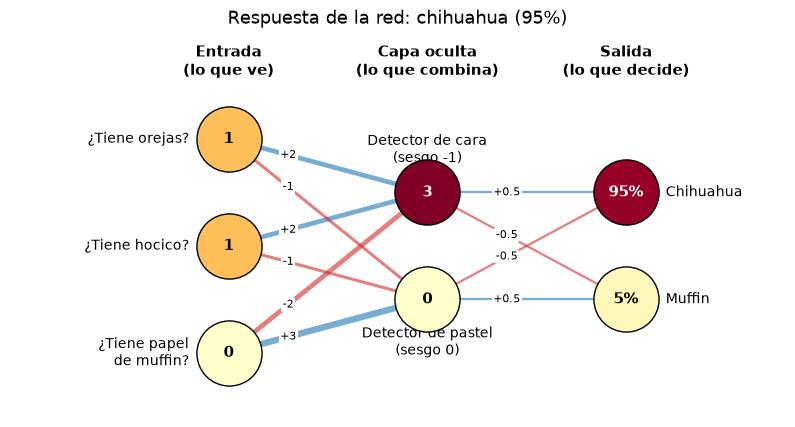

*La red de juguete ante una foto con orejas y hocico. En la celda siguiente puedes cambiar las pistas.*

**Cómo leer el diagrama.** Una línea azul es un peso positivo: empuja a la neurona a encenderse. Una línea roja es un peso negativo: la frena. El grosor muestra la fuerza. El color de cada círculo muestra cuánto se encendió. Marca y desmarca las casillas: ¿qué responde la red si la foto tiene orejas **y** papel de muffin?

In [ ]:
# Pausa teórica A: una red neuronal de juguete (3 entradas, 2 neuronas ocultas, 2 salidas)
ENTRADAS = ["¿Tiene orejas?", "¿Tiene hocico?", "¿Tiene papel\nde muffin?"]
OCULTAS = ["Detector de cara\n(sesgo -1)", "Detector de pastel\n(sesgo 0)"]
RESPUESTAS = ["Chihuahua", "Muffin"]
W1 = torch.tensor([[2., 2., -2.], [-1., -1., 3.]])   # pesos: entrada → capa oculta
B1 = torch.tensor([-1., 0.])                          # sesgos de la capa oculta
W2 = torch.tensor([[.5, -.5], [-.5, .5]])             # pesos: capa oculta → salida

def pasar(x):
    oculta = F.relu(W1 @ x + B1)              # cada neurona: suma ponderada, sesgo y ReLU
    return oculta, F.softmax(W2 @ oculta, 0)  # la salida se convierte en probabilidades

def dibujar_red(orejas=True, hocico=True, papel=False):
    x = torch.tensor([orejas, hocico, papel], dtype=torch.float32)
    oculta, prob = pasar(x)
    capas = [(ENTRADAS, x, "{:.0f}"), (OCULTAS, oculta, "{:.0f}"), (RESPUESTAS, prob, "{:.0%}")]
    pos = [[(k, (len(n) - 1) / 2 - j) for j in range(len(n))] for k, (n, _, _) in enumerate(capas)]

    _, eje = plt.subplots(figsize=(10, 5))
    for k, W in enumerate([W1, W2]):                          # líneas: grosor y color según el peso
        for o, (dx, dy) in enumerate(pos[k + 1]):
            for i, (ox, oy) in enumerate(pos[k]):
                w = W[o, i].item()
                eje.plot([ox, dx], [oy, dy], color="tab:blue" if w > 0 else "tab:red", lw=1 + 1.2 * abs(w), alpha=.6, zorder=1)
                t = .3 if k == 0 else .4
                eje.text(ox + t * (dx - ox), oy + t * (dy - oy), f"{w:+g}", fontsize=8, ha="center", va="center",
                         bbox=dict(fc="white", ec="none", pad=1), zorder=2)
    for k, ((nombres, valores, formato), puntos) in enumerate(zip(capas, pos)):   # círculos: cuánto se encendió
        for nombre, v, (px, py) in zip(nombres, valores.tolist(), puntos):
            brillo = v if k == 2 else min(v / 3, 1)
            eje.scatter(px, py, s=2200, color=plt.cm.YlOrRd(brillo), edgecolors="black", zorder=3)
            eje.text(px, py, formato.format(v), ha="center", va="center", fontsize=11, weight="bold",
                     color="white" if brillo > .6 else "black", zorder=4)
            lado = {0: dict(x=px - .2, y=py, ha="right"), 1: dict(x=px, y=py + (.4 if py > 0 else -.4), ha="center"),
                    2: dict(x=px + .2, y=py, ha="left")}[k]
            eje.text(lado.pop("x"), lado.pop("y"), nombre, va="center", fontsize=10,
                     bbox=dict(fc="white", ec="none", pad=1), zorder=2, **lado)
    for k, titulo in enumerate(["Entrada\n(lo que ve)", "Capa oculta\n(lo que combina)", "Salida\n(lo que decide)"]):
        eje.text(k, 1.6, titulo, ha="center", fontsize=11, weight="bold")
    ganadora = prob.argmax().item()
    respuesta = "no sabe (empate)" if prob.max() < .55 else f"{RESPUESTAS[ganadora].lower()} ({prob[ganadora]:.0%})"
    eje.set_title(f"Respuesta de la red: {respuesta}", fontsize=13)
    eje.set_xlim(-1.1, 2.8); eje.set_ylim(-1.6, 2.0); eje.axis("off")
    plt.show()

widgets.interact(dibujar_red, orejas=True, hocico=True, papel=False);

Aquí escribimos los 12 pesos y sesgos a mano. Al **entrenar**, la red los ajusta sola: prueba, se equivoca, mide el error y corrige un poco cada peso. ResNet18 es esta misma idea a gran escala: 11,7 millones de pesos, y sus entradas no son tres pistas sino los 150.528 números de los píxeles de la foto.

## Pausa teórica, parte B: ¿qué es una CNN y cómo funciona?

Una **CNN** (red neuronal convolucional) es una red neuronal diseñada para imágenes. ResNet18 es una CNN.

**El problema.** Una foto de 224 x 224 píxeles con 3 colores tiene 150.528 números. Una red neuronal común conecta cada neurona con **todos** esos números. Eso exige millones de pesos. Además, la red no sabe que una oreja es una oreja si aparece arriba o abajo de la foto.

**La idea.** Una CNN usa una **lupa pequeña** (un filtro de, por ejemplo, 3 x 3 píxeles) que recorre la foto de izquierda a derecha y de arriba abajo. En cada posición, multiplica los píxeles por los pesos del filtro y suma el resultado. Es el mismo cálculo que hiciste a mano en la misión 2 de la parte 1. El filtro usa **los mismos pesos en toda la foto**: si detecta un borde en una esquina, también lo detecta en el centro.

Una CNN repite cuatro operaciones:

| Operación | Qué hace | Analogía |
|---|---|---|
| Convolución | Cada filtro recorre la imagen y entrega un mapa: claro donde encuentra su patrón | Una lupa que busca un solo tipo de detalle |
| Activación (ReLU) | Convierte los valores negativos en cero | Quedarse solo con las señales a favor |
| Pooling (reducción) | Resume cada bloque de 2 x 2 en su valor máximo; la imagen queda a la mitad | Mirar la foto desde más lejos |
| Capa final | Combina el resumen de toda la foto y entrega una probabilidad por clase | El jurado que vota |

```
foto 224x224x3 → [convolución + ReLU + pooling] x varias veces → huella de 512 números → capa final → ¿muffin o chihuahua?
```

**La jerarquía.** Los primeros filtros detectan bordes y colores. Los siguientes combinan bordes en texturas, las texturas en partes (un ojo, un arándano) y las partes en conceptos.

**El aprendizaje.** Nadie programa los filtros. Al inicio sus pesos son números al azar. En el entrenamiento, la red mira una foto, se equivoca, mide el error y ajusta un poco cada peso para equivocarse menos. Repite esto con miles de fotos.

La celda siguiente aplica las tres primeras operaciones a un muffin, con un filtro de bordes verticales escrito a mano.

In [ ]:
# Pausa teórica: convolución, ReLU y pooling sobre una foto
MUFFIN = next(i for i in range(len(fotos)) if etiquetas[i] == 0)   # el primer muffin
gris = torch.tensor(np.asarray(fotos[MUFFIN].convert("L").resize((224, 224))), dtype=torch.float32) / 255

filtro = torch.tensor([[-1., 0., 1.],
                       [-2., 0., 2.],
                       [-1., 0., 1.]])                          # detector de bordes verticales (Sobel)

conv = F.conv2d(gris[None, None], filtro[None, None], padding=1)   # 1. convolución
activ = F.relu(conv)                                               # 2. activación: negativos a cero
reducido = F.max_pool2d(activ, 2)                                  # 3. pooling: máximo de cada bloque 2 x 2

pasos = {"Foto en gris": gris, "1. Convolución": conv[0, 0], "2. ReLU": activ[0, 0], "3. Pooling": reducido[0, 0]}
fig, ejes = plt.subplots(1, 4, figsize=(15, 4))
for eje, (nombre, m) in zip(ejes, pasos.items()):
    eje.imshow(m, cmap="gray"); eje.set_title(f"{nombre}\n{m.shape[0]} x {m.shape[1]}"); eje.axis("off")
plt.tight_layout(); plt.show()

densa = 224 * 224 * 3 * 64                    # 64 neuronas comunes conectadas a cada número de la foto
convolucional = red.conv1.weight.numel()      # 64 filtros de 7 x 7 x 3 de ResNet18
print(f"Pesos de una capa común con 64 neuronas:      {densa:>12,}".replace(",", "."))
print(f"Pesos de la primera capa convolucional (64):  {convolucional:>12,}".replace(",", "."))
print(f"La capa convolucional usa {densa // convolucional:,} veces menos pesos.".replace(",", "."))

**Pregunta de repaso.** El filtro usa los mismos 9 pesos en toda la foto. ¿Qué ventaja tiene esto frente a tener pesos distintos para cada píxel? ¿Qué filtro escribirías para detectar bordes horizontales?

## Misión 3: abrir la red capa por capa

Una red neuronal es una cadena de pisos. Cada piso recibe números, los combina con sus **pesos** y entrega números nuevos. Los primeros pisos detectan cosas simples; los últimos, conceptos.

### 3a. El primer piso: 64 filtros de 7 x 7 píxeles

En la misión 2 de la parte 1 aplicaste a mano un filtro de bordes. ResNet18 **aprendió sola** 64 filtros así. Míralos.

In [ ]:
# Misión 3a: los 64 filtros que la red aprendió en su primera capa
filtros = red.conv1.weight.detach()                  # forma: 64 filtros x 3 colores x 7 x 7
filtros = (filtros - filtros.min()) / (filtros.max() - filtros.min())

fig, ejes = plt.subplots(4, 16, figsize=(14, 4))
for eje, f in zip(ejes.flat, filtros):
    eje.imshow(f.permute(1, 2, 0)); eje.axis("off")
plt.suptitle("Primera capa: detectores de bordes, rayas y colores"); plt.show()
print(f"Parámetros totales de ResNet18: {sum(p.numel() for p in red.parameters()):,}".replace(",", "."))

### 3b. El viaje de una foto por la red

Ahora seguimos una foto de chihuahua piso a piso. En cada piso mostramos 6 de sus "mapas de activación": zonas claras significan que ese detector se encendió. Fíjate en dos cosas: la imagen se **achica** y los detectores se **multiplican**.

In [ ]:
# Misión 3b: mapas de activación en cada piso
FOTO = next(i for i in range(len(fotos)) if etiquetas[i] == 1)   # el primer chihuahua
x = X[FOTO:FOTO + 1]

pisos = {}
with torch.no_grad():
    h = red.maxpool(red.relu(red.bn1(red.conv1(x)))); pisos["piso 1 (bordes)"] = h
    h = red.layer1(h); pisos["piso 2 (texturas)"] = h
    h = red.layer2(h); pisos["piso 3 (patrones)"] = h
    h = red.layer3(h); pisos["piso 4 (partes)"] = h
    h = red.layer4(h); pisos["piso 5 (conceptos)"] = h

fig, ejes = plt.subplots(len(pisos), 7, figsize=(14, 10))
for fila, (nombre, h) in zip(ejes, pisos.items()):
    fila[0].imshow(fotos[FOTO].resize((224, 224))); fila[0].set_title(nombre, fontsize=9)
    mas_activos = h[0].mean(dim=(1, 2)).topk(6).indices       # los 6 detectores más encendidos
    for eje, c in zip(fila[1:], mas_activos):
        eje.imshow(h[0, c], cmap="magma")
    for eje in fila: eje.axis("off")
plt.tight_layout(); plt.show()

print(f"{'Piso':<20}{'Tamaño del mapa':>18}{'Detectores':>12}")
for nombre, h in pisos.items():
    print(f"{nombre:<20}{f'{h.shape[2]} x {h.shape[3]}':>18}{h.shape[1]:>12}")

### 3c. La huella final: 512 números

El último piso resume la foto entera en **512 números**. Esa lista es la "huella" de la imagen. La red decide comparando huellas. Mira las huellas de 5 chihuahuas y 5 muffins: cada fila es una foto y cada columna, un número.

In [ ]:
# Misión 3c: la huella de 512 números de cada foto
cuerpo = torch.nn.Sequential(*list(copy.deepcopy(red).children())[:-1]).to(DISPOSITIVO)   # copia de la red sin su último piso

with torch.no_grad():
    HUELLAS = torch.cat([cuerpo(X[i:i + 32].to(DISPOSITIVO)).flatten(1).cpu() for i in range(0, len(X), 32)])

perros = [i for i in range(len(fotos)) if etiquetas[i] == 1][:5]
muffins = [i for i in range(len(fotos)) if etiquetas[i] == 0][:5]
plt.figure(figsize=(14, 3.5))
plt.imshow(HUELLAS[perros + muffins, :128], aspect="auto", cmap="viridis")
plt.yticks(range(10), ["chihuahua"] * 5 + ["muffin"] * 5); plt.xlabel("Primeros 128 de los 512 números")
plt.title("Huellas: las filas de una misma clase se parecen"); plt.colorbar(); plt.show()

**Pregunta 3.** El piso 1 ve bordes y el piso 5 ve conceptos. Nadie programó esos detectores: la red los aprendió de los ejemplos. ¿Qué ventaja y qué riesgo tiene que las reglas las invente la máquina y no un ingeniero?

## Misión 4: transfer learning, una tarea nueva en segundos

ResNet18 ya sabe ver bordes, texturas y partes. Solo le falta decidir entre **dos** clases nuevas. La idea es simple: **congelamos** los 17 pisos que ya saben ver y entrenamos solo un piso final nuevo con 512 x 2 pesos más 2.

Separamos 240 fotos para entrenar y 59 para la prueba. La red nunca ve las fotos de prueba al entrenar.

In [ ]:
# Misión 4a: entrenar solo el último piso
N = 240
entrenamiento, prueba = slice(0, N), slice(N, None)

torch.manual_seed(0)                    # mismo punto de partida cada vez que corres la celda
cabeza = torch.nn.Linear(512, 2)        # el piso nuevo
optimizador = torch.optim.Adam(cabeza.parameters(), lr=1e-3)

inicio = time.time()
historial = []
for vuelta in range(30):
    perdida = F.cross_entropy(cabeza(HUELLAS[entrenamiento]), etiquetas[entrenamiento])
    optimizador.zero_grad(); perdida.backward(); optimizador.step()
    historial.append(perdida.item())

with torch.no_grad():
    acierto = (cabeza(HUELLAS[prueba]).argmax(1) == etiquetas[prueba]).float().mean().item()

entrenados = sum(p.numel() for p in cabeza.parameters())
print(f"Pesos entrenados: {entrenados:,}".replace(",", ".") + " de 11,7 millones")
print(f"Tiempo: {time.time() - inicio:.1f} s  |  Acierto en prueba: {acierto:.0%}")
plt.figure(figsize=(6, 3)); plt.plot(historial); plt.xlabel("Vuelta de entrenamiento"); plt.ylabel("Error"); plt.title("La red aprende"); plt.show()

### 4b. La comparación: entrenar desde cero

¿Y si usamos la misma red pero **sin** lo que aprendió en ImageNet? Entrenamos los 11,7 millones de pesos con solo 240 fotos. Toma entre 15 segundos (con GPU) y 3 minutos (sin GPU). Si tienes poco tiempo, cambia `ENTRENAR_DESDE_CERO` a `False`.

In [ ]:
# Misión 4b: la misma red, desde cero
ENTRENAR_DESDE_CERO = True

if ENTRENAR_DESDE_CERO:
    torch.manual_seed(0)
    novata = models.resnet18(num_classes=2).to(DISPOSITIVO)
    opt = torch.optim.Adam(novata.parameters(), lr=1e-3)
    inicio = time.time()
    for vuelta in range(5):
        novata.train()
        for i in range(0, N, 32):
            perdida = F.cross_entropy(novata(X[i:i + 32].to(DISPOSITIVO)), etiquetas[i:i + 32].to(DISPOSITIVO))
            opt.zero_grad(); perdida.backward(); opt.step()
    novata.eval()
    with torch.no_grad():
        acierto_cero = (novata(X[prueba].to(DISPOSITIVO)).argmax(1).cpu() == etiquetas[prueba]).float().mean().item()
    print(f"Desde cero      : {acierto_cero:.0%} en {time.time() - inicio:.0f} s")
print(f"Transfer learning: {acierto:.0%}")

**Pregunta 4.** Una empresa quiere clasificar fotos de sus productos y tiene solo 300 fotos etiquetadas. Con lo que viste, ¿qué le recomiendas: contratar a alguien que entrene un modelo desde cero o adaptar uno existente? ¿Qué preguntarías sobre el modelo de origen?

## Misión 5: ¿dónde mira la red?

Que acierte no basta: queremos saber **por qué** acierta. Unimos el cuerpo congelado con la cabeza nueva para tener el clasificador completo.

### 5a. Oclusión a mano

Tapa una zona de la foto con un cuadrado gris y mira cómo cambia la confianza. Mueve los controles: si tapas los ojos o la nariz del perro, ¿la red duda?

In [ ]:
# Misión 5a: tapar una zona y ver qué pasa
clasificador = torch.nn.Sequential(cuerpo.cpu(), torch.nn.Flatten(), cabeza).eval()
MEDIA = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
DESV = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
ver = lambda t: (t * DESV + MEDIA).permute(1, 2, 0).clamp(0, 1)     # tensor normalizado a imagen visible
probar = list(range(N, len(fotos)))                           # fotos de prueba

def tapar(foto=0, columna=80, fila=60, lado=60):
    i = probar[foto]
    x = X[i].clone()
    x[:, fila:fila + lado, columna:columna + lado] = 0              # 0 = gris medio tras normalizar
    with torch.no_grad():
        antes = F.softmax(clasificador(X[i:i + 1]), 1)[0, 1].item()
        despues = F.softmax(clasificador(x[None]), 1)[0, 1].item()
    _, ejes = plt.subplots(1, 2, figsize=(8, 4))
    ejes[0].imshow(ver(X[i])); ejes[0].set_title(f"Original: {antes:.0%} chihuahua")
    ejes[1].imshow(ver(x)); ejes[1].set_title(f"Tapada: {despues:.0%} chihuahua")
    for e in ejes: e.axis("off")
    plt.show()

widgets.interact(tapar,
    foto=widgets.IntSlider(0, 0, len(probar) - 1),
    columna=widgets.IntSlider(80, 0, 200, 10), fila=widgets.IntSlider(60, 0, 200, 10),
    lado=widgets.IntSlider(60, 20, 160, 10));

### 5b. Mapas de calor automáticos con Captum

Captum es la librería de interpretabilidad de PyTorch. Hace dos cosas que tú hiciste a mano y otras que no podríamos hacer a mano:

| Método | Idea |
|---|---|
| Oclusión | Tapa cada zona de la foto, una por una, y mide cuánto cae la confianza |
| Gradientes integrados | Pasa de una foto negra a la foto real y suma qué píxeles empujaron la decisión |

Rojo intenso significa "esta zona fue importante para la respuesta".

In [ ]:
# Misión 5b: mapas de calor de 4 fotos de prueba (2 perros y 2 muffins)
oclusion, gradientes = Occlusion(clasificador), IntegratedGradients(clasificador)
elegidas = [i for i in probar if etiquetas[i] == 1][:2] + [i for i in probar if etiquetas[i] == 0][:2]

fig, ejes = plt.subplots(len(elegidas), 3, figsize=(10, 3.3 * len(elegidas)))
for fila, i in zip(ejes, elegidas):
    x = X[i:i + 1]
    with torch.no_grad():
        clase = clasificador(x).argmax(1).item()
    mapa_o = oclusion.attribute(x, target=clase, sliding_window_shapes=(3, 32, 32), strides=(3, 16, 16))
    mapa_g = gradientes.attribute(x, target=clase, n_steps=32)
    fila[0].imshow(ver(X[i])); fila[0].set_title(f"Respuesta: {CLASES[clase]}")
    for eje, mapa, nombre in [(fila[1], mapa_o, "Oclusión"), (fila[2], mapa_g, "Gradientes integrados")]:
        crudo = mapa.sum(1, keepdim=True).clamp(min=0) if nombre == "Oclusión" else mapa.abs().sum(1, keepdim=True)
        calor = F.avg_pool2d(crudo, 9, 1, 4)[0, 0].detach()  # suaviza el mapa
        calor = (calor / calor.quantile(0.99)).clamp(max=1)
        eje.imshow(ver(X[i]), alpha=0.5); eje.imshow(calor, cmap="Reds", alpha=0.6); eje.set_title(nombre)
    for e in fila: e.axis("off")
plt.tight_layout(); plt.savefig(SALIDAS / "mapas_de_calor.png", dpi=120); plt.show()

**Pregunta 5.** Compara los mapas con las pistas que anotaste en la misión 1. ¿La red mira lo mismo que tú? ¿Hay zonas del fondo marcadas en rojo? Imagina un modelo que aprueba créditos o detecta tumores: ¿por qué un regulador pediría ver mapas como estos antes de aprobarlo?

## Misión 6: revisar los datos con ojo crítico

Un modelo es tan bueno como sus ejemplos. Pedimos a la red las 8 fotos sobre las que tiene **menos certeza**, usando todo el dataset. Mira bien qué hay en cada foto y qué etiqueta tiene.

In [ ]:
# Misión 6: las fotos más dudosas del dataset
with torch.no_grad():
    p_perro = F.softmax(cabeza(HUELLAS), 1)[:, 1]
dudosas = (p_perro - 0.5).abs().argsort()[:8]

fig, ejes = plt.subplots(2, 4, figsize=(14, 7))
for eje, i in zip(ejes.flat, dudosas.tolist()):
    eje.imshow(fotos[i]); eje.axis("off")
    eje.set_title(f"Etiqueta: {CLASES[etiquetas[i]]}\nRed: {p_perro[i]:.0%} chihuahua", fontsize=9)
plt.tight_layout(); plt.show()

**Pregunta 6.** En el dataset original, la clase "muffin" incluye fotos que no son muffins: arbustos de arándanos, zanahorias o huevos. ¿Quién etiquetó estos datos y con qué criterio? ¿Qué pasaría si tu empresa entrena un modelo con etiquetas así? Propón una regla de control de calidad.

## Cierre

| Lo que viste | Lo que significa para el negocio |
|---|---|
| La red aprende sus propios detectores, de bordes a conceptos | No hay reglas escritas: hay que auditar con ejemplos |
| Un modelo responde con confianza aunque la categoría no exista | La confianza no es lo mismo que la verdad |
| Transfer learning acierta casi siempre con 240 fotos y un piso nuevo | Adaptar un modelo existente es más barato que crear uno |
| Captum muestra dónde mira la red | La explicabilidad es posible y se puede exigir |
| Las etiquetas del dataset tienen errores | La calidad de los datos define la calidad del modelo |

**Fuente de datos:** dataset `sasha/chihuahua-muffin` de Hugging Face (299 fotos). Su ficha no declara licencia; úsalo solo con fines docentes.